# Principal Component Analysis of dermatological images

Dermatological images are primarily dominated by the red color channel.  Using this information may (somewhat) reduce the complexity and memory of any deep-learning algorithm.  Here we explore the potential use of Pricipal Components Analysis (PCA) as an image preprocessing step to achieve this within our deep-learning pipeline.

Note that this notebook ***should never*** touch the validation or test datasets so an not to overfit the eventual models.

In [1]:
# Import relevant libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

Here we demonstrate the reg-green-blue (RGB) channels for an example input image.

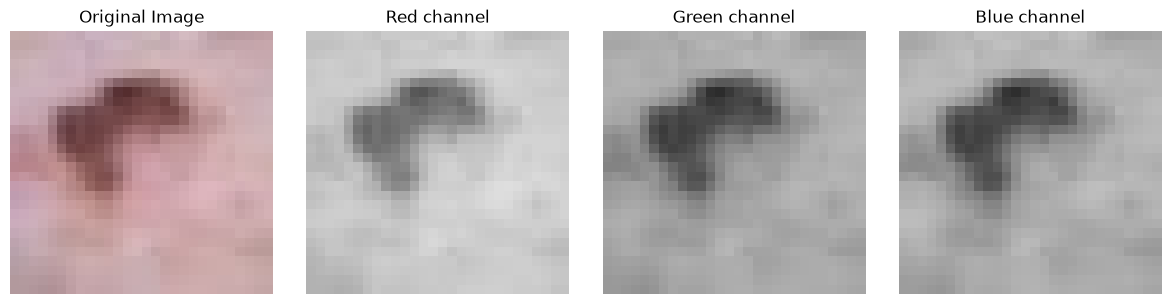

In [8]:
train_images = np.load("../data/raw_data/train_images.npy")

# Extract a single slice and its RGB channels
slice_idx = 10
slice_data = train_images[slice_idx]
red = slice_data[..., 0]
green = slice_data[..., 1]
blue = slice_data[..., 2]

# Plot within a single figure
_, axs = plt.subplots(1, 4, figsize=(12, 3))
axs[0].imshow(slice_data)
axs[0].set_title("Original Image")

axs[1].imshow(red, cmap='gray', clim = (0, 255))
axs[1].set_title("Red channel")

axs[2].imshow(green, cmap='gray', clim = (0, 255))
axs[2].set_title("Green channel")

axs[3].imshow(blue, cmap='gray', clim = (0, 255))
axs[3].set_title("Blue channel")

for ax in axs:
    ax.axis('off')

plt.tight_layout()
plt.show()

On the training data, we will now fit a PCA and explore the space

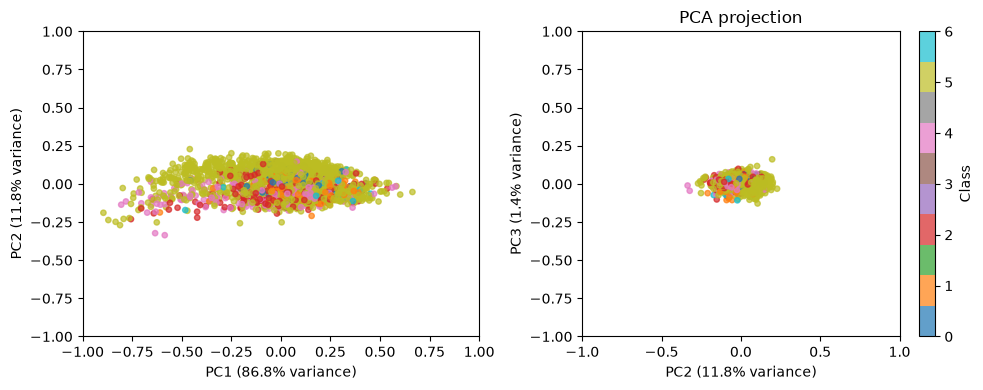

In [21]:
# Extract the labels for the data
train_labels = np.load("../data/raw_data/train_labels.npy").ravel()
pixels_per_image = train_images.shape[1] * train_images.shape[2]
pixel_labels = np.repeat(train_labels, pixels_per_image)

# Reshape the data for PCA
reshaped_data = train_images.reshape(-1, 3).astype(np.float32) / 255.0  # Reshape to (num_pixels, 3) and normalize

# Fit the PCA model
pca = PCA(n_components=3)
pca.fit(reshaped_data)

# Transform a random selection of data (not all as will take long to render the plot)
np.random.seed(42)  # For reproducibility
random_indices = np.random.choice(reshaped_data.shape[0], size=2000, replace=False)
transformed_data = pca.transform(reshaped_data[random_indices])

_, axs = plt.subplots(1, 2, figsize=(10, 4))

for i in (1, 2):
    scatter = axs[i-1].scatter(
        transformed_data[:, i-1],
        transformed_data[:, i],
        c=pixel_labels[random_indices],
        cmap="tab10",
        alpha=0.7,
        s=15,
    )
    axs[i-1].set_xlabel(f"PC{i} ({pca.explained_variance_ratio_[i-1]:.1%} variance)")
    axs[i-1].set_ylabel(f"PC{i+1} ({pca.explained_variance_ratio_[i]:.1%} variance)")
    axs[i-1].set_xlim((-1, 1)), axs[i-1].set_ylim((-1, 1))

plt.title("PCA projection")
plt.colorbar(scatter, label="Class")
plt.tight_layout()
plt.show()

We see that this has successfully found that most of the image variation can be determined from a single channel.

Next we will observe how inverting the PCA can recover the original image.

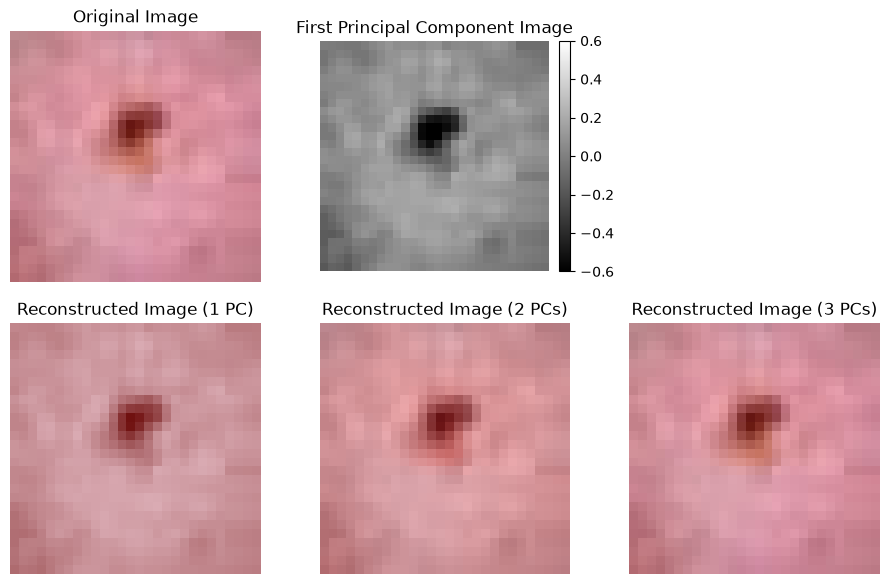

In [49]:
image_index = 900

original = train_images[image_index].astype(np.float32) / 255.0
pixels = original.reshape(-1, 3)

# Convert RGB pixels into PCA coordinates.
scores = pca.transform(pixels)

# Plot reconstructions for increasing numbers of principal components.
_, axs = plt.subplots(2, 3, figsize=(9, 6))
for i, num_components in enumerate([1, 2, 3]):
    # Retain only the first principal component.
    component_scores = np.zeros_like(scores)

    for j in range(num_components):
        component_scores[:, j] = scores[:, j]

    # Convert back to RGB and restore the image shape.
    reconstructed_pixels = pca.inverse_transform(component_scores)
    reconstructed_image = reconstructed_pixels.reshape(original.shape)

    reconstructed_image = np.clip(reconstructed_image, 0.0, 1.0) * 255.0  # Scale back to [0, 255]
    reconstructed_image = reconstructed_image.astype(np.uint8)  # Convert to uint8 for display

    axs[1, i].imshow(reconstructed_image)
    axs[1, i].set_title(f"Reconstructed Image ({num_components} PC{'s' if num_components > 1 else ''})")

# Show the original image in the first subplot.
axs[0, 0].imshow(original)
axs[0, 0].set_title("Original Image")

# Also demonstrate the image of the first principal component, which is a grayscale image.
first_pc_image = scores[:, 0].reshape(original.shape[0], original.shape[1])
image = axs[0, 1].imshow(first_pc_image, cmap='gray', clim = (-0.6, 0.6))
axs[0, 1].set_title("First Principal Component Image")
plt.colorbar(image, ax=axs[0, 1], fraction=0.046, pad=0.04)

for ax in axs.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

We see that much of the information is seen in the first PCA component and that the third offers very little additional information.